# Creating Root files for hackathon

In [5]:
import argparse
import sys

import awkward as ak
import numpy as np
import uproot
import vector

vector.register_awkward()

In [19]:
with open("Top.txt") as f:
    files = [line.strip() for line in f if line.strip()]

files = files[0:40]

In [20]:
files

['root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_t-channel_top_4f_InclusiveDecays_TuneCP5_13TeV-powheg-madspin-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v1/100000/0164285F-F384-CD43-B796-F66C21D36DEF.root',
 'root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_t-channel_top_4f_InclusiveDecays_TuneCP5_13TeV-powheg-madspin-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v1/100000/06BCFF43-D370-B540-B4C1-9F0FE4DB0E23.root',
 'root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_t-channel_top_4f_InclusiveDecays_TuneCP5_13TeV-powheg-madspin-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v1/100000/6E5A9D23-BE8A-F140-91EC-7E2FDA28E712.root',
 'root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_t-channel_top_4f_InclusiveDecays_TuneCP5_13TeV-powheg-madspin-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v1/100000/7D10EA67-C43C-224F-ABFF-E295F3565AE3.root',
 'root://eospublic.cern.ch//eos/opendata

In [21]:
len(files)

40

In [22]:
total = 0
for f in files:
    try:
        with uproot.open(f) as rf:
            n = rf[tree_name].num_entries
#         print(f"{f}: {n}")
        total += n
    except Exception as e:
        print(f"FAILED {f}: {e}")

print("Total events:", total)

Total events: 7746000


In [3]:
tree_name = "Events"
output_file = "bvcoe_samples_2/WW-test.root"

In [292]:
keep_branches = ["Electron_pt", "Electron_eta", "Electron_phi", "Electron_mass", 
        "Electron_mvaFall17V2Iso_WP90", "Electron_charge",
        
        "Muon_pt", "Muon_eta", "Muon_phi", "Muon_mass", 
        "Muon_tightId", "Muon_charge", "Muon_pfRelIso04_all",
        "PuppiMET_pt", "PuppiMET_phi",
        
        "Jet_pt", "Jet_eta", "Jet_phi", "Jet_mass",
        "Jet_btagDeepFlavB", "nJet", "Jet_jetId", "Jet_puId",]
calc_branches = []

In [293]:
BAD = -999.0 # value for variables where a variable is undefined
BAD_jet = 0.0

In [294]:
def to_flat(x, mask=None):
    """awkward -> flat float32 numpy array; events outside mask get BAD."""
    x = ak.to_numpy(ak.fill_none(x, BAD)).astype(np.float32)
    if mask is not None:
        x = np.where(ak.to_numpy(mask), x, np.float32(BAD))
    return x

# def 
# 

def to_flat_jet(x, mask=None):
    x = ak.to_numpy(ak.fill_none(x, BAD_jet)).astype(np.float32)
    if mask is not None:
        x = np.where(ak.to_numpy(mask), x, BAD_jet)
    return x



In [295]:
def wrap_angle_to_pi(angle):
        return (angle + np.pi) % (2 * np.pi) - np.pi
 
 
def create_lepton_vector(lepton):
    """4-vector from lepton properties (vector.zip works with awkward records)."""
    return vector.zip({
        "pt": lepton.pt,
        "eta": lepton.eta,
        "phi": lepton.phi,
        "mass": lepton.mass,
    })
 
 
def cal_kinematic_var(leading, subleading, met):
    lepton_1 = create_lepton_vector(leading)
    lepton_2 = create_lepton_vector(subleading)
    dilepton = lepton_1 + lepton_2
 
    masses = dilepton.mass
    ptll = dilepton.pt
    dphi = wrap_angle_to_pi(leading.phi - subleading.phi)
 
    # Higgs transverse mass
    mt_higgs_dphi = wrap_angle_to_pi(dilepton.phi - met.phi)
    mt_higgs = np.sqrt(2 * ptll * met.pt * (1 - np.cos(mt_higgs_dphi)))
 
    # Lepton 2 transverse mass
    mt_l2_met_dphi = wrap_angle_to_pi(subleading.phi - met.phi)
    mt_l2_met = np.sqrt(2 * subleading.pt * met.pt * (1 - np.cos(mt_l2_met_dphi)))
 
    return masses, ptll, dphi, mt_higgs, mt_l2_met
 
 
def calculate_mjj(jets):
    n_jets = ak.num(jets)
    mjj = ak.zeros_like(n_jets, dtype=float)
    has_two_jets = n_jets >= 2
    if ak.any(has_two_jets):
        jets_padded = ak.pad_none(jets, 2, axis=1)
        jet_vectors = ak.zip({
            "pt": ak.fill_none(jets_padded.pt, 0.0),
            "eta": ak.fill_none(jets_padded.eta, 0.0),
            "phi": ak.fill_none(jets_padded.phi, 0.0),
            "mass": ak.fill_none(jets_padded.mass, 0.0),
        }, with_name="Momentum4D")
        jet1 = jet_vectors[:, 0]
        jet2 = jet_vectors[:, 1]
        dijet = jet1 + jet2
        mjj = ak.where(has_two_jets, dijet.mass, 0.0)
    return mjj
 


In [296]:
def select_tight_leptons(arrays):
    """Apply tight ID and isolation cuts to leptons"""
    tight_electron_mask = arrays.Electron_mvaFall17V2Iso_WP90 == 1
    tight_muon_mask = (arrays.Muon_tightId == 1) & (arrays.Muon_pfRelIso04_all < 0.15)
 
    tight_electrons = ak.zip({
        "pt": arrays.Electron_pt[tight_electron_mask],
        "eta": arrays.Electron_eta[tight_electron_mask],
        "phi": arrays.Electron_phi[tight_electron_mask],
        "mass": arrays.Electron_mass[tight_electron_mask],
        "charge": arrays.Electron_charge[tight_electron_mask],
        "flavor": ak.ones_like(arrays.Electron_pt[tight_electron_mask]) * 11
    })
 
    tight_muons = ak.zip({
        "pt": arrays.Muon_pt[tight_muon_mask],
        "eta": arrays.Muon_eta[tight_muon_mask],
        "phi": arrays.Muon_phi[tight_muon_mask],
        "mass": arrays.Muon_mass[tight_muon_mask],
        "charge": arrays.Muon_charge[tight_muon_mask],
        "flavor": ak.ones_like(arrays.Muon_pt[tight_muon_mask]) * 13
    })
 
    tight_leptons = ak.concatenate([tight_electrons, tight_muons], axis=1)
    return tight_leptons, tight_electron_mask, tight_muon_mask
 
 
def choose_leading_subleading(tight_leptons):
    """Sort tight leptons by pT, return leading, subleading (no selection cuts).
    Events with < 2 tight leptons get zeros and has2 = False."""
    sorted_leptons = tight_leptons[ak.argsort(tight_leptons.pt, axis=1, ascending=False)]
    four = ak.zip({"pt": sorted_leptons.pt, "eta": sorted_leptons.eta,
                   "phi": sorted_leptons.phi, "mass": sorted_leptons.mass})
    has2 = ak.num(four, axis=1) >= 2
    padded = ak.pad_none(four, 2, axis=1)
    zero = {"pt": 0.0, "eta": 0.0, "phi": 0.0, "mass": 0.0}
    leading = ak.fill_none(padded[:, 0], zero, axis=0)
    subleading = ak.fill_none(padded[:, 1], zero, axis=0)
    return leading, subleading, has2
 
 
def count_jets(arrays, jet_pt_threshold=30, tight_leptons=None):
    jets = ak.zip({
        "pt": arrays.Jet_pt,
        "eta": arrays.Jet_eta,
        "phi": arrays.Jet_phi,
        "mass": arrays.Jet_mass,
        "jetId": arrays.Jet_jetId,
        "btagDeepFlavB": arrays.Jet_btagDeepFlavB,
        "puId": arrays.Jet_puId
    })
    pu_id_mask = (jets.pt > 50) | ((jets.pt <= 50) & (jets.puId >= 4))
    good_mask = (jets.jetId >= 2) & (abs(jets.eta) < 4.7) & pu_id_mask
 
    if tight_leptons is not None and ak.max(ak.num(tight_leptons)) > 0:
        jets_eta = jets.eta[:, :, None]
        jets_phi = jets.phi[:, :, None]
        leps_eta = tight_leptons.eta[:, None, :]
        leps_phi = tight_leptons.phi[:, None, :]
 
        deta = jets_eta - leps_eta
        dphi = (jets_phi - leps_phi + np.pi) % (2 * np.pi) - np.pi
        dr = np.sqrt(deta**2 + dphi**2)
 
        min_dr = ak.min(dr, axis=-1)
        min_dr = ak.fill_none(min_dr, 999.0)
        good_mask = good_mask & (min_dr > 0.4)
 
    good_jets = jets[good_mask]
    sorted_jets = good_jets[ak.argsort(good_jets.pt, axis=1, ascending=False)]
    lead_jet_pt = ak.fill_none(ak.firsts(sorted_jets.pt), 0)
    sublead_jet_pt = ak.fill_none(ak.firsts(sorted_jets[:, 1:].pt), 0)
 
    isZeroJet = (lead_jet_pt < jet_pt_threshold)
    isOneJet = (lead_jet_pt >= jet_pt_threshold) & (sublead_jet_pt < jet_pt_threshold)
    isTwoJet = (sublead_jet_pt >= jet_pt_threshold)
 
    n_jets = ak.sum(sorted_jets.pt >= jet_pt_threshold, axis=1)
    return n_jets, good_mask, sorted_jets, isZeroJet, isOneJet, isTwoJet


In [297]:
def select_e_mu_events(tight_leptons, met_arrays, leading_pt_cut=15, subleading_pt_cut=5):
    """Select events with exactly 1 tight electron and 1 tight muon, opposite sign.
    Returns: leading, subleading, met (all for selected events only), and
    evt_mask (full-length boolean mask over the input events)."""
    sorted_leptons = tight_leptons[ak.argsort(tight_leptons.pt, axis=1, ascending=False)]

    # exactly 2 tight leptons
    mask_2lep = ak.num(sorted_leptons, axis=1) == 2
    if ak.sum(mask_2lep) == 0:
        return None, None, None, None

    events_2lep = sorted_leptons[mask_2lep]
    met_2lep = met_arrays[mask_2lep]

    leading = events_2lep[:, 0]
    subleading = events_2lep[:, 1]

    # 1 electron + 1 muon
    mask_1e1mu = ((leading.flavor == 11) & (subleading.flavor == 13)) | \
                 ((leading.flavor == 13) & (subleading.flavor == 11))

    # opposite charge
    mask_opposite_charge = leading.charge * subleading.charge < 0

    # pT cuts
    mask_pt_lead = leading.pt > leading_pt_cut
    mask_pt_sublead = ((subleading.flavor == 11) & (subleading.pt > 13)) | \
                      ((subleading.flavor == 13) & (subleading.pt > subleading_pt_cut))
    mask_pt = mask_pt_lead & mask_pt_sublead

    # eta cuts
    eta_leading = ((leading.flavor == 11) & (abs(leading.eta) < 2.5)) | \
                  ((leading.flavor == 13) & (abs(leading.eta) < 2.4))
    eta_subleading = ((subleading.flavor == 11) & (abs(subleading.eta) < 2.5)) | \
                     ((subleading.flavor == 13) & (abs(subleading.eta) < 2.4))
    mask_eta = eta_leading & eta_subleading

    final_mask = mask_1e1mu & mask_opposite_charge & mask_pt & mask_eta

    # map the 2-lepton-subset mask back to the full chunk
    evt_mask = np.zeros(len(tight_leptons), dtype=bool)
    evt_mask[np.flatnonzero(ak.to_numpy(mask_2lep))[ak.to_numpy(final_mask)]] = True

    return leading[final_mask], subleading[final_mask], met_2lep[final_mask], evt_mask


In [298]:
def jet_slot(jets, i, field):
    """i-th jet's field as a flat float32 array; -999 if the event has fewer jets."""
    return to_flat_jet(ak.pad_none(jets, i + 1, axis=1)[:, i][field])

first = True
with uproot.recreate(output_file) as fout:
    for a in uproot.iterate({f: tree_name for f in files},
                            filter_name=keep_branches + calc_branches,
                            step_size="100 MB", library="ak"):

        tight_leptons, _, _ = select_tight_leptons(a)
        met_all = ak.zip({"pt": a["PuppiMET_pt"], "phi": a["PuppiMET_phi"]})

        leading, subleading, met, evt_mask = select_e_mu_events(tight_leptons, met_all)
        if evt_mask is None or evt_mask.sum() == 0:
            continue

        a = a[evt_mask]
        tight_leptons = tight_leptons[evt_mask]

        n_jets, _, sorted_jets, isZeroJet, isOneJet, isTwoJet = count_jets(
            a, tight_leptons=tight_leptons)

        # good jets above the jet threshold, already pT-sorted
        jets30 = sorted_jets[sorted_jets.pt >= 30]

        mll, ptll, dphi, mth, mtw2 = cal_kinematic_var(leading, subleading, met)

        out = {
            # pT-ordered leptons
            "Lepton1_pt":  to_flat(leading.pt),
            "Lepton1_eta": to_flat(leading.eta),
            "Lepton1_phi": to_flat(leading.phi),
            "Lepton2_pt":  to_flat(subleading.pt),
            "Lepton2_eta": to_flat(subleading.eta),
            "Lepton2_phi": to_flat(subleading.phi),

            # leading / subleading good jets (-999 if absent)
            "Jet1_pt":  jet_slot(jets30, 0, "pt"),
            "Jet1_eta": jet_slot(jets30, 0, "eta"),
            "Jet1_phi": jet_slot(jets30, 0, "phi"),
            "Jet2_pt":  jet_slot(jets30, 1, "pt"),
            "Jet2_eta": jet_slot(jets30, 1, "eta"),
            "Jet2_phi": jet_slot(jets30, 1, "phi"),

            # MET
            "PuppiMET_pt":  to_flat(a["PuppiMET_pt"]),
            "PuppiMET_phi": to_flat(a["PuppiMET_phi"]),

            # kinematic variables
            "mll":    to_flat(mll),
            "ptll":   to_flat(ptll),
            "dphill": to_flat(dphi),
            "mth":    to_flat(mth),
            "mtw2":   to_flat(mtw2),
            "mjj":    to_flat(calculate_mjj(sorted_jets)),   # -999 if < 2 jets

            "njet":    ak.to_numpy(n_jets).astype(np.int32),
            "jet_cat": (ak.to_numpy(isOneJet).astype(np.int32)
                        + 2 * ak.to_numpy(isTwoJet).astype(np.int32)),  # 0 / 1 / 2 (>=2)
        }

        print(f"kept {evt_mask.sum()} / {len(evt_mask)}")

        if first:
            fout["Events"] = out
            first = False
        else:
            fout["Events"].extend(out)
print("\n\nDONE")

kept 9143 / 81000
kept 126049 / 1135000
kept 65698 / 588000


DONE


In [299]:
print("Done ->", output_file)

Done -> bvcoe_samples_2/WW-test.root


In [109]:
import uproot

# url = "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/Higgs0Mf05ph0ToWW_M-125_TuneCP5_13TeV-powheg-jhugen727-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v2/40000/2600A354-96F9-4C48-99FA-D77C85CB7806.root"
url = "bvcoe_samples/Top-train.root"
with uproot.open(url) as f:
    print(f.keys())
    print(f["Events"].num_entries)

['Events;1']
20453


In [ ]:
for arrays in uproot.iterate(
    {url: "Events"},
    expressions=["Electron_pt", "Muon_pt"],
    step_size="100 MB",
    library="ak",
):
    print("Chunk:", len(arrays))
    print(arrays.fields)
    break

Number of entries: 531601
Minimum: 0.0
Maximum: 1901.0


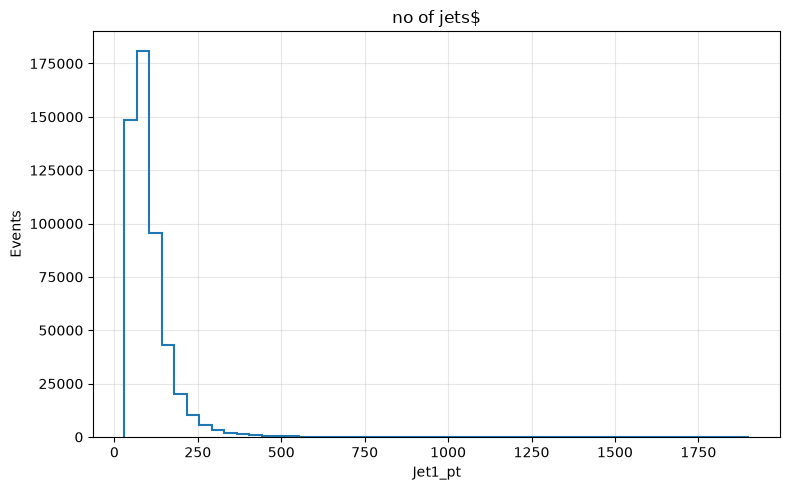

In [173]:
import uproot
import matplotlib.pyplot as plt
import numpy as np


with uproot.open("bvcoe_samples/Top-test.root") as f:
#     jet_cat0= Jet1_pt[jet_cat==0]
    mll = f["Events"].arrays(["Jet1_pt"], library="np")["Jet1_pt"]
    jet_cat= f["Events"].arrays(["jet_cat"], library="np")["jet_cat"]

print("Number of entries:", len(mll))
print("Minimum:", np.min(mll))
print("Maximum:", np.max(mll))

plt.figure(figsize=(8, 5))

plt.hist(
    mll[jet_cat > 0],
    bins=50,
#     range=(-, 20),
    histtype="step",
    linewidth=1.5
)

plt.xlabel(r"Jet1_pt")
plt.ylabel("Events")
plt.title(r"no of jets$")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
with uproot.open("bvcoe_samples_2/Top-test.root") as f:
    print(f.keys())
    b = f["Events"]
    print(b.num_entries)
    for branches in b.keys():
        print(branches)

['Events;1']
23902
Jet1_eta
Jet1_phi
Jet1_pt
Jet2_eta
Jet2_phi
Jet2_pt
Lepton1_eta
Lepton1_phi
Lepton1_pt
Lepton2_eta
Lepton2_phi
Lepton2_pt
PuppiMET_phi
PuppiMET_pt
dphill
jet_cat
mjj
mll
mth
mtw2
njet
ptll


In [29]:
print(uproot.__version__)

5.7.1


In [25]:
# Calculating weights for the training
# formula = xsec*lumi/no of events 


Ne = {"Higgs":957_000,
     "DY":38_974_113,
     "WW":1_804_000,
     "Top":7_746_000}

xsec = {"Higgs":1.0315,
     "DY":6189.39,
     "WW":12.178,
     "Top":87.310}

lumi = 10

W ={}

for sample in Ne:
    W[sample] = (xsec[sample]*1000*lumi)/Ne[sample]
    print(f"sample {sample}; weight = {W[sample]:.6f}")

sample Higgs; weight = 0.010778
sample DY; weight = 1.588077
sample WW; weight = 0.067506
sample Top; weight = 0.112716
